# Block 1: S&P 500 Returns

**Objective.** Describe the return profile of the S&P 500 over 2015–2026: price path,
daily simple and log returns, summary statistics and annualized growth.

**Data.** Daily closes of the S&P 500 index (`^GSPC`, Yahoo Finance), 2015-01-02 to 2026-10-30.
`^GSPC` is a *price* index: dividends are not included, so total shareholder return is higher
than the figures reported here.

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.ticker as mticker
import numpy as np
from volrisk.config import TRADING_DAYS
from volrisk.config import FIGURES
from volrisk.data import load_raw
from volrisk.returns import simple_returns, log_returns, cagr, summary_stats

In [14]:
prices = load_raw("sp500")["Close"]

# Test the data loading and display the first few rows of the prices DataFrame
prices.head()

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.


Date
2015-01-02    2058.199951
2015-01-05    2020.579956
2015-01-06    2002.609985
2015-01-07    2025.900024
2015-01-08    2062.139893
Name: Close, dtype: float64

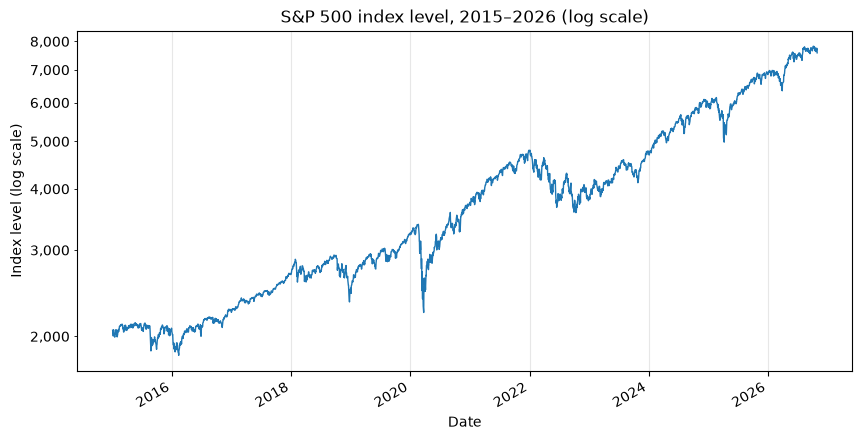

In [15]:
# Plot the S&P 500 index level on a log scale
fig, ax = plt.subplots(figsize=(10, 5))

# The width of the line is set to 1 for better visibility, and the y-axis is set to a logarithmic scale to represent equal percentage moves more clearly. The plot is titled and labeled appropriately, and a grid is added for better readability. Finally, the figure is saved to the specified directory with a resolution of 150 dpi and tight bounding box, and the plot is displayed.
prices.plot(ax=ax, linewidth=1)
ax.set_yscale("log")  # equal vertical distances = equal percentage moves
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_minor_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("S&P 500 index level, 2015–2026 (log scale)")
ax.set_xlabel("Date")
ax.set_ylabel("Index level (log scale)")
ax.grid(alpha=0.3)

# Save the figure
FIGURES.mkdir(exist_ok=True)
fig.savefig(FIGURES / "01_sp500_price.png", dpi=150, bbox_inches="tight")
plt.show()

The index roughly quadrupled over the period, with sharp drawdowns in 2018, March 2020 (COVID-19),
2022 and April 2025. These episodes are analyzed systematically in Block 4.

## Daily returns: simple vs. log

Two return definitions are used throughout the project:

- **Simple return:** `R_t = P_t / P_(t-1) - 1`, which measures the realized percentage gain or loss.
- **Log return:** `r_t = ln(P_t / P_(t-1)) = ln(1 + R_t)`.

Log returns are time-additive: the log return over several days is the sum of the daily log returns.
This makes them the standard choice for statistical analysis and volatility estimation
(Campbell, Lo & MacKinlay, 1997). For small daily moves, log and simple returns are almost equal;
they diverge on extreme days, such as March 2020.

In [16]:
# Daily simple and log returns
simple_ret = simple_returns(prices)
log_ret = log_returns(prices)

# Sanity check: one return per trading day, except the first
print(f"Prices: {len(prices)} | Simple returns: {len(simple_ret)} | Log returns: {len(log_ret)}")

Prices: 2975 | Simple returns: 2974 | Log returns: 2974


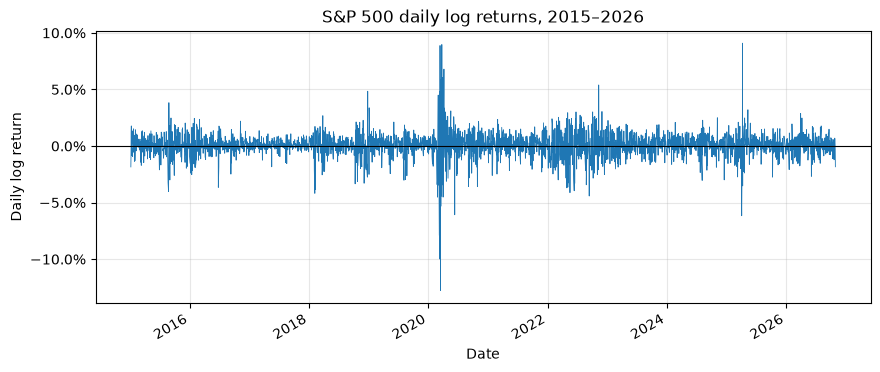

In [17]:
# Plot daily log returns
fig, ax = plt.subplots(figsize=(10, 4))

log_ret.plot(ax=ax, linewidth=0.6)
ax.axhline(0, color="black", linewidth=0.8)  # zero line
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))  # 0.05 -> 5%
ax.set_title("S&P 500 daily log returns, 2015–2026")
ax.set_xlabel("Date")
ax.set_ylabel("Daily log return")
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "01_sp500_daily_returns.png", dpi=150, bbox_inches="tight")
plt.show()

Large moves cluster in time: calm periods (2017, 2019) alternate with turbulent ones
(February 2018, March 2020, 2022, April 2025). This volatility clustering is one of the
stylized facts of asset returns (Cont, 2001) and is examined formally in Block 3.

In [18]:
# Summary statistics of daily simple and log returns, side by side
stats = pd.concat([summary_stats(simple_ret), summary_stats(log_ret)], axis=1)
stats

,simple_return,log_return
n_obs,2974,2974
mean,0.0005,0.000438
std,0.011091,0.011119
min,-0.119841,-0.127652
min_date,2020-03-16 00:00:00,2020-03-16 00:00:00
max,0.095154,0.090895
max_date,2025-04-09 00:00:00,2025-04-09 00:00:00
skewness,-0.356478,-0.643704
excess_kurtosis,15.092511,15.923829


### Reading the summary statistics

Daily returns show two classic **stylized facts** of asset returns (Cont, 2001):

- **Negative skewness:** large losses are more extreme than large gains. The worst day
  (16 March 2020, COVID-19 crash) is deeper than the best day (9 April 2025, tariff-pause rally).
  Skewness is more negative for log returns (−0.64) than for simple returns (−0.36), because the
  log transformation stretches losses and compresses gains, so the return definition matters.
- **Fat tails:** excess kurtosis is about 15, versus 0 for a normal distribution. Extreme days
  are far more frequent than a Gaussian model predicts, a feature first documented by
  Mandelbrot (1963).

These properties matter for risk measurement: a normal-based VaR will underestimate tail
losses (Block 5).

In [19]:
# Three ways to annualize performance, and the volatility drag
vol_annual = log_ret.std() * np.sqrt(TRADING_DAYS)

annualization = pd.Series({
    "CAGR (geometric)": cagr(prices),
    "Mean log return x 252, then exp - 1": np.exp(log_ret.mean() * TRADING_DAYS) - 1,
    "Mean simple return x 252 (arithmetic)": simple_ret.mean() * TRADING_DAYS,
    "Annualized volatility": vol_annual,
    "Volatility drag (sigma^2 / 2)": vol_annual**2 / 2,
}, name="value")

annualization.map("{:.2%}".format)

CAGR (geometric)                         11.66%
Mean log return x 252, then exp - 1      11.68%
Mean simple return x 252 (arithmetic)    12.60%
Annualized volatility                    17.65%
Volatility drag (sigma^2 / 2)             1.56%
Name: value, dtype: str

### Annualized performance: three measures and the volatility drag

Three annualized measures are reported because they answer different questions:

- **CAGR (geometric):** `(P_end / P_start)^(1 / years) - 1`, the growth rate an investor
  actually earned by holding the index. It is the reference measure of realized performance.
- **Mean log return x 252:** the continuously compounded growth rate. Converted back with
  `exp(.) - 1`, it matches the CAGR (11.68% vs 11.66%; the small gap comes from the 252-day
  convention versus about 251.6 actual trading days per year). It serves as a cross-check and is
  consistent with the log returns used in the statistical analysis.
- **Mean simple return x 252 (arithmetic):** the expected one-period return, widely used in
  mean-variance analysis. It overstates the growth an investor actually experiences over time.

**Volatility drag.** Arithmetic and compounded returns are linked by:

    arithmetic mean ≈ continuously compounded growth rate + sigma^2 / 2

With an annualized volatility of 17.65%, the drag is sigma^2 / 2 = 1.56%, which is exactly the gap
between the arithmetic mean (12.60%) and the continuously compounded growth rate (11.04%).
Volatility therefore reduces long-run compounded growth: the more volatile the asset, the larger
the gap between its average return and the return investors actually earn
(Booth & Fama, 1992).

In [20]:
# Five worst and five best trading days (simple returns, i.e. actual daily % moves)
extreme_days = pd.DataFrame({
    "worst_day": simple_ret.nsmallest(5).index.date,
    "worst_return": simple_ret.nsmallest(5).values,
    "best_day": simple_ret.nlargest(5).index.date,
    "best_return": simple_ret.nlargest(5).values,
})

extreme_days.style.format({"worst_return": "{:.2%}", "best_return": "{:.2%}"})

,worst_day,worst_return,best_day,best_return
0,2020-03-16,-11.98%,2025-04-09,9.52%
1,2020-03-12,-9.51%,2020-03-24,9.38%
2,2020-03-09,-7.60%,2020-03-13,9.29%
3,2025-04-04,-5.97%,2020-04-06,7.03%
4,2020-06-11,-5.89%,2020-03-26,6.24%


### Extreme days

Eight of the ten most extreme days occurred between March and June 2020, and the other two in
April 2025. The best days closely follow the worst ones (for example, -9.51% on 12 March 2020
followed by +9.29% the next day; -5.97% on 4 April 2025 followed by +9.52% on 9 April).
Extreme returns cluster in turbulent periods rather than being spread evenly over time,
another illustration of volatility clustering (Cont, 2001). An investor who exits the market
after a large loss is therefore likely to miss the strongest rebounds.

## Block 1: key takeaways

- The S&P 500 grew at a **CAGR of 11.66%** (price only, excluding dividends) from January 2015
  to October 2026, with an annualized volatility of **17.65%**.
- Daily returns are **negatively skewed** and **fat-tailed** (excess kurtosis about 15):
  a normal distribution is a poor description of equity returns (Mandelbrot, 1963; Cont, 2001).
- The arithmetic mean overstates compounded growth by the **volatility drag** (sigma^2 / 2 = 1.56%
  per year) (Booth & Fama, 1992).
- Large moves **cluster in time**, which motivates the rolling volatility analysis of **Block 2**.